# Quick Sort — Grupo 4
**Fatec Ourinhos · Ciência de Dados · Algoritmos de Ordenação e Busca**
Profa. Jéssica Delgado · 2026

Integrantes: Vitor Augusto Neias, Gabriel Gulia, Marco Albano e João Miguel.

Objetivo: implementar o Quick Sort e medir seu desempenho na ordenação da coluna
"número de veículos envolvidos" do dataset Datatran 2024.

**Como executar:** coloque o arquivo `datatran2024.csv` em `/content/` e use
*Ambiente de execução → Executar tudo*.

In [1]:
# Importando bibliotecas
import pandas as pd
import matplotlib.pyplot as plt
import time
import random
import sys


## Carregamento do dataset
Leitura do Datatran 2024 (separador `;` e codificação `latin1`).
A base possui 60.365 registros. A leitura é feita uma única vez e fica fora das
medições de tempo, como orientam as boas práticas.  

Fonte: github.com/AndersonSalata/projeto-integrado-ciencia-de-dados.

In [2]:
# Importando dataset
df = pd.read_csv('/content/datatran2024.csv', sep=';', encoding='latin1', low_memory=False)


In [3]:
# Visualizando as cincos primeiras linhas
df.head()

,id,data_inversa,dia_semana,horario,uf,br,km,municipio,causa_acidente,tipo_acidente,...,feridos_graves,ilesos,ignorados,feridos,veiculos,latitude,longitude,regional,delegacia,uop
0,571789,01/01/2024,segunda-feira,03:56:00,ES,101,38,CONCEICAO DA BARRA,Ultrapassagem Indevida,Colisão lateral sentido oposto,...,1,1,1,1,3,"-18,48261","-39,92379",SPRF-ES,DEL04-ES,UOP02-DEL04-ES
1,571804,01/01/2024,segunda-feira,04:50:00,PI,343,185,PIRIPIRI,Manobra de mudança de faixa,Colisão frontal,...,0,1,0,0,2,"-4,29603281","-41,76732659",SPRF-PI,DEL02-PI,UOP01-DEL02-PI
2,571806,01/01/2024,segunda-feira,04:30:00,BA,116,578,BREJOES,Ingestão de álcool pelo condutor,Colisão frontal,...,0,1,2,0,4,"-13,07158302","-39,9611107",SPRF-BA,DEL03-BA,UOP02-DEL03-BA
3,571818,01/01/2024,segunda-feira,06:30:00,SE,101,18,MALHADA DOS BOIS,Reação tardia ou ineficiente do condutor,Saída de leito carroçável,...,1,0,2,1,3,"-10,35601949","-36,90552235",SPRF-SE,DEL02-SE,UOP02-DEL02-SE
4,571838,01/01/2024,segunda-feira,05:00:00,MT,364,240,RONDONOPOLIS,Condutor deixou de manter distância do veículo...,Colisão traseira,...,0,2,1,0,3,"-16,17914141","-54,78905337",SPRF-MT,DEL02-MT,UOP01-DEL02-MT


## E3 — Seleção da coluna
Conforme o roteiro, usamos **somente** a coluna `veiculos` (número de veículos
envolvidos). Ela é convertida em lista Python, a estrutura que o algoritmo ordena.

In [4]:
# Convertendo a coluna veiculos para lista
lista_veiculos = df['veiculos'].tolist()
print(len(lista_veiculos)) # quantidade de registros
print(lista_veiculos[:10]) # 10 primeiros valores
print(type(lista_veiculos)) # conferindo se esta em lista


60365
[3, 2, 4, 3, 3, 3, 2, 5, 2, 1]
<class 'list'>


In [5]:
# Criando fatias

entrada_5k = lista_veiculos[:5000]
entrada_10k = lista_veiculos[:10000]
entrada_15k = lista_veiculos[:15000]
entrada_20k = lista_veiculos[:20000]
entrada_30k = lista_veiculos[:30000]

### Distribuição dos valores
A coluna tem apenas **19 valores distintos**, e quase metade dos registros vale 2.
Esse grande número de repetições afeta diretamente o desempenho do Quick Sort,
como mostram os resultados mais adiante.

In [6]:
print(df['veiculos'].nunique()) # quantos valores diferentes existem?
print(df['veiculos'].value_counts()) # quantas vezes cada valor aparece


19
veiculos
2     29092
1     19832
3      6982
4      2617
5      1072
6       354
7       186
8       105
9        37
10       33
11       19
12       10
13       10
15        5
14        5
16        2
17        2
20        1
26        1
Name: count, dtype: int64


## E2 — Implementação

### Versão clássica (partição de Lomuto)
O pivô é o último elemento. A partição move para a esquerda os elementos ≤ pivô
e coloca o pivô na posição final. Depois, o `quicksort` ordena recursivamente
os lados esquerdo e direito.

In [7]:

def particao_lomuto(lista, inicio, fim):
  pivo = lista[fim]
  i = inicio - 1
  for j in range(inicio, fim):
    if lista[j] <= pivo:
      i += 1
      lista[i], lista[j] = lista[j], lista[i]
  lista[i + 1], lista[fim] = lista[fim], lista[i + 1]
  return i + 1


In [8]:
def quicksort(lista, inicio, fim):
  if inicio < fim:
    pivo = particao_lomuto(lista, inicio, fim)
    quicksort(lista, inicio, pivo - 1)
    quicksort(lista, pivo + 1, fim)


### Testes de corretude — versão clássica
Comparamos o resultado com o `sorted()` do Python em 100 listas aleatórias.

In [9]:

teste = [7, 2, 9, 4, 3, 8]
quicksort(teste, 0, len(teste) - 1)
print(teste)

for _ in range(100):
  original = [random.randint(1, 100) for _ in range(50)]
  copia = original[:]
  quicksort(copia, 0, len(copia) - 1)
  assert copia == sorted(original)
print('Todos os testes passaram')

[2, 3, 4, 7, 8, 9]
Todos os testes passaram


### Teste da versão clássica com os dados reais
Com o limite padrão de recursão do Python (1000), a versão clássica gera
`RecursionError`. Com tantos valores repetidos, cada partição fica muito
desbalanceada e a recursão chega a milhares de níveis: é o pior caso do algoritmo.

In [10]:

# Teste com os dados reais (limite padrão de recursão = 1000)
try:
  copia = entrada_5k[:]
  quicksort(copia, 0, len(copia) - 1)
  print('Ordenou!', copia == sorted(entrada_5k))
except RecursionError:
  print('RecursionError: a versão clássica estourou o limite de recursão do Python')

RecursionError: a versão clássica estourou o limite de recursão do Python


### Variante: partição em 3 vias (Dijkstra)
Divide a lista em três partes: **menores**, **iguais** e **maiores** que o pivô
(escolhido aleatoriamente). O bloco dos iguais já fica na posição final e não entra
na recursão, o que resolve o problema dos valores repetidos.

In [11]:
def particao_3vias(lista, inicio, fim):
  pivo = lista[random.randint(inicio, fim)]   # pivô aleatório
  lt, i, gt = inicio, inicio, fim
  # lista[inicio..lt-1] < pivo | lista[lt..i-1] == pivo | lista[gt+1..fim] > pivo
  while i <= gt:
    if lista[i] < pivo:
      lista[lt], lista[i] = lista[i], lista[lt]
      lt += 1
      i += 1
    elif lista[i] > pivo:
      lista[i], lista[gt] = lista[gt], lista[i]
      gt -= 1        # i não avança: o elemento que veio de gt ainda não foi analisado
    else:
      i += 1
  return lt, gt      # início e fim do bloco de iguais

def quicksort_3vias(lista, inicio, fim):
  if inicio < fim:
    lt, gt = particao_3vias(lista, inicio, fim)
    quicksort_3vias(lista, inicio, lt - 1)     # só os menores
    quicksort_3vias(lista, gt + 1, fim)        # só os maiores

for nome, entrada in [("5k", entrada_5k), ("10k", entrada_10k), ("30k", entrada_30k)]:
  copia = entrada[:]
  quicksort_3vias(copia, 0, len(copia) - 1)
  print(nome, copia == sorted(entrada))

5k True
10k True
30k True


### Testes de corretude — versão 3 vias
Comparamos o resultado com o `sorted()` do Python em três situações:
100 listas aleatórias (valores de 1 a 100), 100 listas com muitos valores repetidos
(de 1 a 5, como na coluna `veiculos`) e casos extremos (lista vazia, um elemento
e todos os elementos iguais).

In [12]:
# Testes de corretude da versão 3 vias
teste = [7, 2, 9, 4, 3, 8]
quicksort_3vias(teste, 0, len(teste) - 1)
print(teste)   # esperado: [2, 3, 4, 7, 8, 9]

# 100 listas aleatórias com valores de 1 a 100
for _ in range(100):
  original = [random.randint(1, 100) for _ in range(50)]
  copia = original[:]
  quicksort_3vias(copia, 0, len(copia) - 1)
  assert copia == sorted(original)

# 100 listas com MUITOS valores repetidos (de 1 a 5), parecido com a coluna veiculos
for _ in range(100):
  original = [random.randint(1, 5) for _ in range(50)]
  copia = original[:]
  quicksort_3vias(copia, 0, len(copia) - 1)
  assert copia == sorted(original)

# Casos extremos: lista vazia, um elemento, todos iguais
for original in [[], [1], [2, 2, 2, 2, 2]]:
  copia = original[:]
  quicksort_3vias(copia, 0, len(copia) - 1)
  assert copia == sorted(original)

print('Todos os testes da 3 vias passaram')

[2, 3, 4, 7, 8, 9]
Todos os testes da 3 vias passaram


## E4 — Medição de tempo

### Configuração da máquina
Ambiente: Google Colab · CPU Intel Xeon 2.20 GHz · 12 GB de RAM.

In [13]:
# Conferindo as config

!lscpu | grep 'Model name'
!free -h
print(sys.version)

Model name:                              Intel(R) Xeon(R) CPU @ 2.20GHz
               total        used        free      shared  buff/cache   available
Mem:            12Gi       1.2Gi       9.0Gi       4.3Mi       2.8Gi        11Gi
Swap:             0B          0B          0B
3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


### Ajuste do limite de recursão
Para conseguir medir a versão clássica, aumentamos o limite de recursão do Python.
A necessidade desse ajuste já mostra uma limitação da versão clássica.

In [14]:
# recursão versão clássica



sys.setrecursionlimit(100000)

### Metodologia
- Os dados já estão carregados em memória; só a ordenação é cronometrada (`time.perf_counter`).
- Cada execução ordena uma **cópia nova** da entrada.
- O resultado é a **média** das execuções: **5 repetições** na versão clássica e
  **100 repetições** na 3 vias (os tempos da 3 vias são da ordem de milissegundos
  e sofrem mais com ruído).
- Tamanhos: 5.000, 10.000, 15.000, 20.000 e 30.000 registros.  

- Antes de cada medição, o algoritmo é executado uma vez sem cronometrar
  (aquecimento), para evitar que a primeira execução distorça a média.

In [15]:
def medir(funcao, entrada, repeticoes=5):
  funcao(entrada[:], 0, len(entrada) - 1)   # aquecimento: roda 1 vez sem medir
  tempos = []
  for _ in range(repeticoes):
    copia = entrada[:]
    inicio = time.perf_counter()
    funcao(copia, 0, len(copia) - 1)
    tempos.append(time.perf_counter() - inicio)
  return sum(tempos) / len(tempos) # média

In [16]:
resultados = []
for n, entrada in [(5000, entrada_5k), (10000, entrada_10k), (15000, entrada_15k),
                   (20000, entrada_20k), (30000, entrada_30k)]:
  t_lomuto = medir(quicksort, entrada)
  t_3vias = medir(quicksort_3vias, entrada, repeticoes=100)
  resultados.append({'n': n, 'lomuto_s': t_lomuto, '3vias_s': t_3vias})
  print(f'n={n}: Lomuto={t_lomuto:.4f}s | 3 vias={t_3vias:.4f}s')

tabela = pd.DataFrame(resultados)
tabela

n=5000: Lomuto=0.9494s | 3 vias=0.0018s
n=10000: Lomuto=2.0981s | 3 vias=0.0039s
n=15000: Lomuto=4.1703s | 3 vias=0.0052s
n=20000: Lomuto=7.9336s | 3 vias=0.0086s
n=30000: Lomuto=19.8644s | 3 vias=0.0131s


,n,lomuto_s,3vias_s
0,5000,0.949357,0.001849
1,10000,2.098061,0.003862
2,15000,4.170268,0.005221
3,20000,7.933572,0.008610
4,30000,19.864432,0.013123


In [17]:
# Verificando a complexidade na prática
tabela['lomuto / n²'] = tabela['lomuto_s'] / tabela['n']**2   # constante → O(n²)
tabela['3vias / n'] = tabela['3vias_s'] / tabela['n']         # constante → linear
tabela['3vias mais rápida (x)'] = tabela['lomuto_s'] / tabela['3vias_s']
tabela

,n,lomuto_s,3vias_s,lomuto / n²,3vias / n,3vias mais rápida (x)
0,5000,0.949357,0.001849,3.797428e-08,3.698424e-07,513.384641
1,10000,2.098061,0.003862,2.098061e-08,3.862468e-07,543.191987
2,15000,4.170268,0.005221,1.853453e-08,3.480967e-07,798.680062
3,20000,7.933572,0.008610,1.983393e-08,4.304830e-07,921.473406
4,30000,19.864432,0.013123,2.207159e-08,4.374474e-07,1513.662659


## E5 — Gráfico (n × tempo)
À esquerda, escala linear; à direita, escala logarítmica, que permite ver as duas
versões, já que a 3 vias é muito mais rápida.

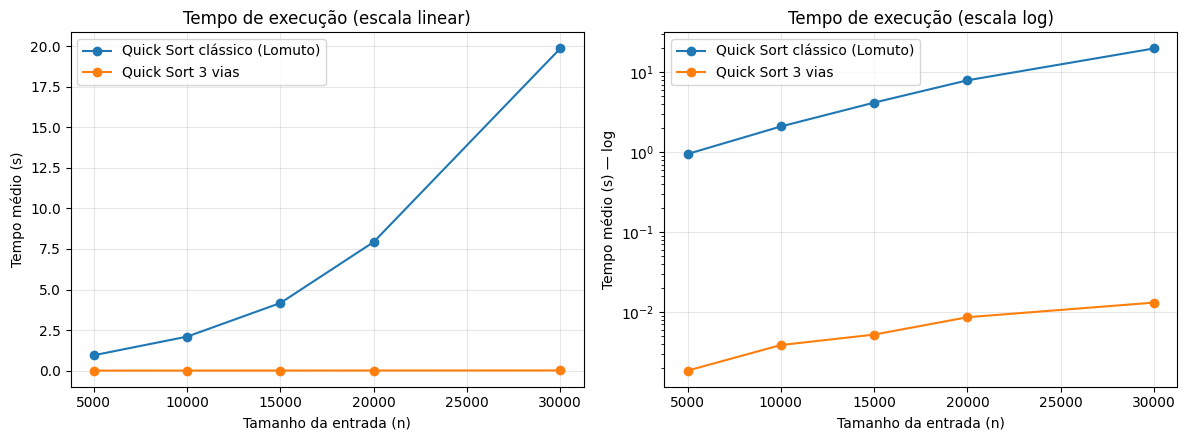

In [18]:

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4.5))

# Gráfico 1: escala normal
ax1.plot(tabela["n"], tabela["lomuto_s"], marker="o", label="Quick Sort clássico (Lomuto)")
ax1.plot(tabela["n"], tabela["3vias_s"], marker="o", label="Quick Sort 3 vias")
ax1.set_title("Tempo de execução (escala linear)")
ax1.set_xlabel("Tamanho da entrada (n)")
ax1.set_ylabel("Tempo médio (s)")
ax1.legend()
ax1.grid(alpha=0.3)

# Gráfico 2: mesmo dado, eixo Y em escala logarítmica
ax2.plot(tabela["n"], tabela["lomuto_s"], marker="o", label="Quick Sort clássico (Lomuto)")
ax2.plot(tabela["n"], tabela["3vias_s"], marker="o", label="Quick Sort 3 vias")
ax2.set_yscale("log")
ax2.set_title("Tempo de execução (escala log)")
ax2.set_xlabel("Tamanho da entrada (n)")
ax2.set_ylabel("Tempo médio (s) — log")
ax2.legend()
ax2.grid(alpha=0.3)

plt.tight_layout()
plt.savefig("grafico_quicksort.png", dpi=150)
plt.show()

In [20]:
# Proporções usadas na análise
r = tabela.set_index('n')
print(f"Clássica  5k → 10k (n ×2): tempo ×{r.loc[10000,'lomuto_s'] / r.loc[5000,'lomuto_s']:.1f}")
print(f"Clássica 10k → 30k (n ×3): tempo ×{r.loc[30000,'lomuto_s'] / r.loc[10000,'lomuto_s']:.1f}")
print(f"Clássica 10k → 20k (n ×2): tempo ×{r.loc[20000,'lomuto_s'] / r.loc[10000,'lomuto_s']:.1f}")
print(f"3 vias    5k → 10k (n ×2): tempo ×{r.loc[10000,'3vias_s'] / r.loc[5000,'3vias_s']:.1f}")
print(f"3 vias   10k → 30k (n ×3): tempo ×{r.loc[30000,'3vias_s'] / r.loc[10000,'3vias_s']:.1f}")
print(f"Em 30k: clássica = {r.loc[30000,'lomuto_s']:.2f} s | 3 vias = {r.loc[30000,'3vias_s']:.4f} s"
      f" | 3 vias {r.loc[30000,'lomuto_s'] / r.loc[30000,'3vias_s']:.0f}× mais rápida")

Clássica  5k → 10k (n ×2): tempo ×2.2
Clássica 10k → 30k (n ×3): tempo ×9.5
Clássica 10k → 20k (n ×2): tempo ×3.8
3 vias    5k → 10k (n ×2): tempo ×2.1
3 vias   10k → 30k (n ×3): tempo ×3.4
Em 30k: clássica = 19.86 s | 3 vias = 0.0131 s | 3 vias 1514× mais rápida


## Análise dos resultados
- **Versão clássica (Lomuto):** de 10k para 20k (n ×2), o tempo multiplicou por ≈ 3,8;
  de 10k para 30k (n ×3), por ≈ 9,5. O esperado para O(n²) seria 4 e 9.
  O valor de tempo ÷ n² ficou quase constante (entre 1,85 e 2,21 × 10⁻⁸ de 10k a 30k),
  o que confirma o crescimento **O(n²)**, o pior caso do Quick Sort.
- **Ponto fora da curva:** em 5k, a versão clássica levou 0,95 s (tempo ÷ n² = 3,8 × 10⁻⁸,
  cerca do dobro dos demais). Em outras execuções, esse mesmo ponto levou ≈ 0,4 s, o que
  indica ruído da máquina compartilhada, e não comportamento do algoritmo.
- **Versão 3 vias:** o tempo multiplicou por ≈ 2,1 (n ×2) e ≈ 3,4 (n ×3), e tempo ÷ n
  ficou entre 3,5 e 4,4 × 10⁻⁷: crescimento praticamente **linear**.
  Com só 19 valores distintos, a recursão fica rasa.
- Em 30.000 registros, a versão 3 vias foi ≈ **1.514 vezes mais rápida**
  (19,86 s contra 0,0131 s).

**Conclusão:** o desempenho do Quick Sort depende dos dados. Com muitos valores
repetidos, a versão clássica cai no pior caso, e a partição em 3 vias resolve isso.

**Limitação:** o Colab é uma máquina compartilhada, então os tempos absolutos variam
entre execuções, como mostra o ponto de 5k. Por isso a análise considera a tendência
do conjunto de pontos (tempo ÷ n² e tempo ÷ n), e não um par isolado.